In [4]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

In [ ]:
# 1 ЗАГРУЗКА КАРТИНКИ

In [5]:
image = cv2.imread('sar_1_gray.jpg')

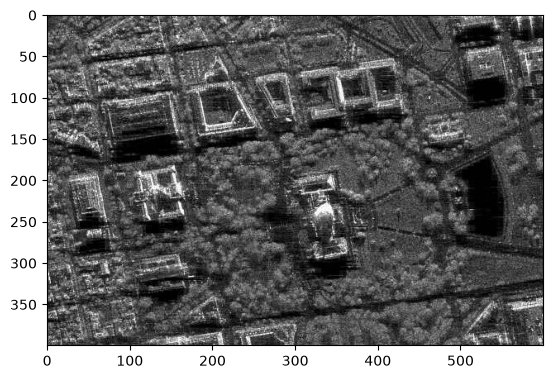

In [14]:
plt.imshow(image)

In [ ]:
# 2 ГИСТОГРАММЫ

In [11]:
b,g,r = cv2.split(image)

In [12]:
histSize = 256
histRange = (0, 256)
accumulate = False

b_hist = cv2.calcHist([b], [0], None, [histSize], histRange, accumulate=accumulate)

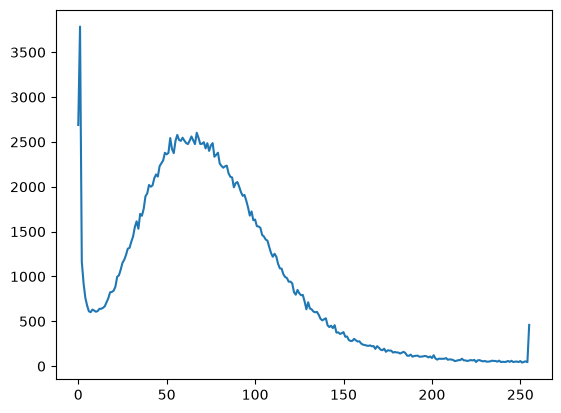

In [13]:
plt.plot(b_hist)

In [15]:
b_hist_cum = b_hist.cumsum()

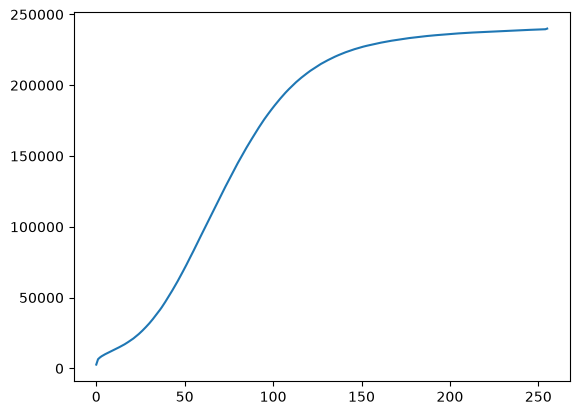

In [16]:
plt.plot(b_hist_cum)

In [17]:
b_hist_norm = b_hist /  (image.shape[0] * image.shape[1])

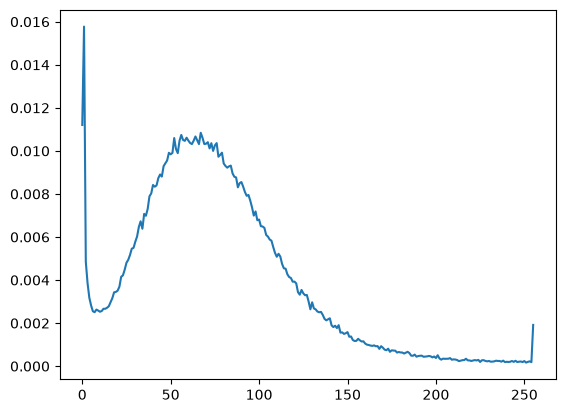

In [18]:
plt.plot(b_hist_norm)

In [ ]:
# 3 ГАММА КОРРЕКЦИЯ

In [19]:
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

In [22]:
gamma = 0.3

img_float = image_gray.astype(np.float32) / 255.0 
img_gamma = np.power(img_float, gamma)
img_corrected_1 = (img_gamma * 255).astype(np.uint8)

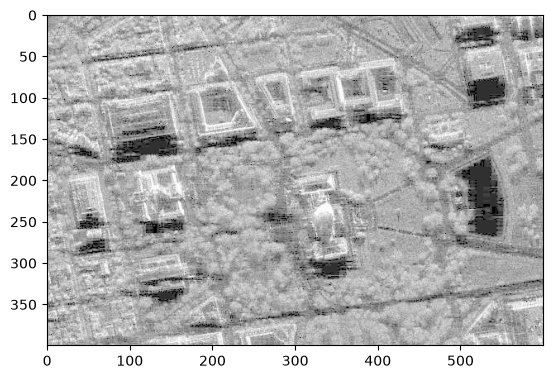

In [15]:
plt.imshow(img_corrected_1)

In [23]:
gamma = 1.7

img_float = image_gray.astype(np.float32) / 255.0
img_gamma = np.power(img_float, gamma)
img_corrected_2 = (img_gamma * 255).astype(np.uint8)

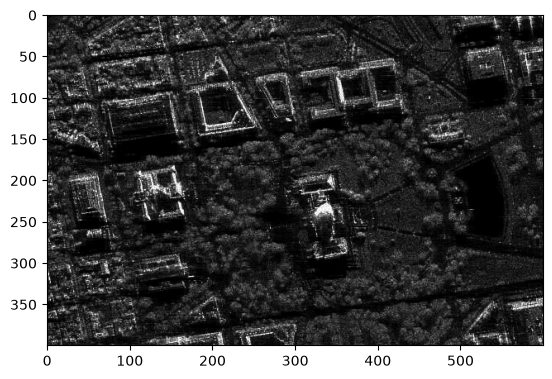

In [17]:
plt.imshow(img_corrected_2)

In [ ]:
# 4 СРАВНЕНИЕ С ПОМОЩЬЮ ГАММА ФИЛЬТРА

In [24]:
from skimage.metrics import structural_similarity, mean_squared_error

(ssim, diff) = structural_similarity(image_gray, img_corrected_1, full=True)
diff = (diff * 255).astype("uint8")
print("SSIM: {}".format(ssim))

SSIM: 0.621872695528399


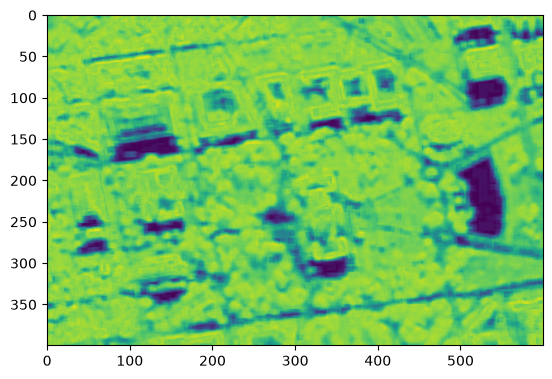

In [25]:
plt.imshow(diff)

In [26]:
mse = mean_squared_error(image_gray, image_gray)
mse

np.float64(0.0)

In [27]:
from skimage.metrics import structural_similarity, mean_squared_error

(ssim, diff) = structural_similarity(image_gray, img_corrected_2, full=True)
diff = (diff * 255).astype("uint8")
print("SSIM: {}".format(ssim))

SSIM: 0.6885057320629194


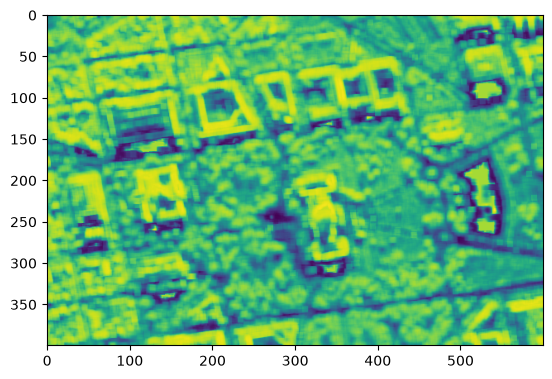

In [28]:
plt.imshow(diff)

In [29]:
mse = mean_squared_error(image_gray, image_gray)
mse

np.float64(0.0)

In [ ]:
# 5 СТАТИСТИЧЕСКАЯ ЦВЕТОКОРРЕКЦИЯ

In [30]:
eq_gray = cv2.equalizeHist(image_gray)

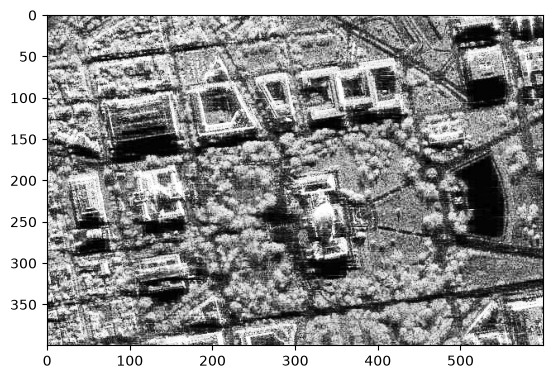

In [31]:
plt.imshow(eq_gray, cmap="gray")

In [39]:
mean_1 = image_gray.mean()

In [40]:
std_1 = image_gray.std()

In [41]:
print(mean_1,std_1)

74.94157083333333 43.658465466227916


In [42]:
mean_2 = eq_gray.mean()

In [43]:
std_2 = eq_gray.std()

In [44]:
print(mean_2,std_2)

127.02563333333333 74.26964841889017


In [66]:
corrected = (eq_gray.astype(np.float32) - mean_1) * (std_2 / std_1) + mean_2

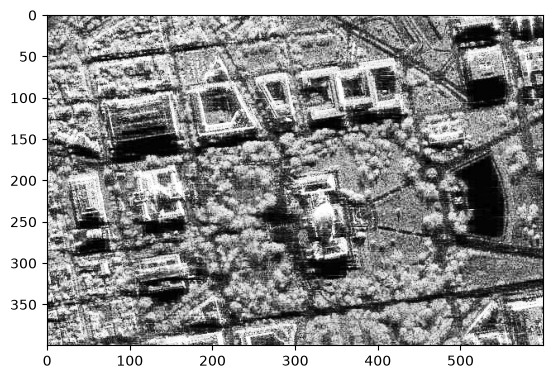

In [67]:
plt.imshow(corrected, cmap='gray')

In [ ]:
# 6 ПОРОГОВАЯ ФИЛЬТРАЦИЯ

In [48]:
_,thresh1 = cv2.threshold(image_gray,200,255,cv2.THRESH_BINARY)

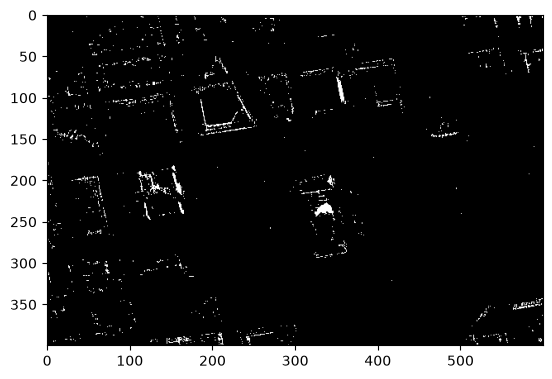

In [49]:
plt.imshow(thresh1, cmap='gray')

In [50]:
thresh1[thresh1==100].sum()

np.uint64(0)

In [51]:
_,thresh2 = cv2.threshold(image_gray,150,255,cv2.THRESH_BINARY)

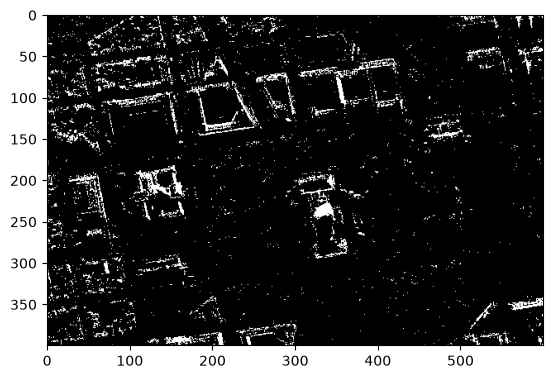

In [52]:
plt.imshow(thresh2, cmap='gray')

In [56]:
_,thresh3 = cv2.threshold(image_gray,100,255,cv2.THRESH_BINARY)

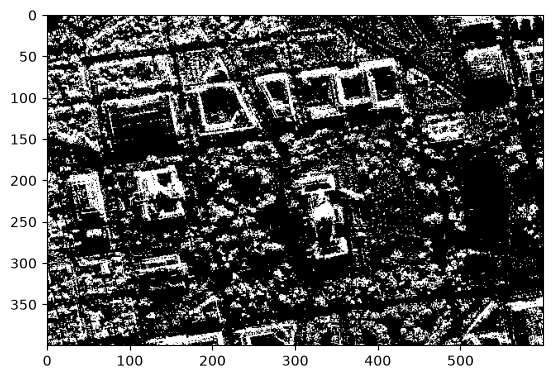

In [57]:
plt.imshow(thresh3, cmap='gray')

In [58]:
_,thresh4 = cv2.threshold(image_gray,50,255,cv2.THRESH_BINARY)

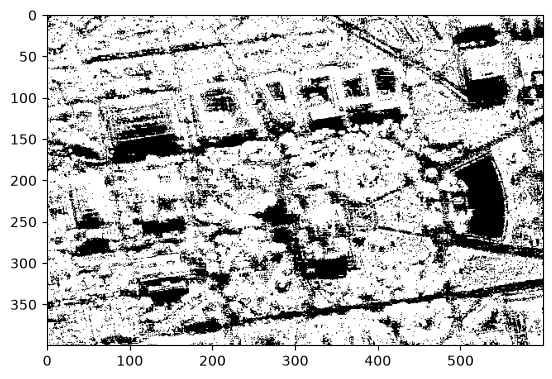

In [59]:
plt.imshow(thresh4, cmap='gray')